# 2. Semantic Segmentation

## Simple Concept

Semantic segmentation is an image segmentation technique that assigns a class label to every pixel in an image.

It identifies **what each pixel represents**, such as a car, road, person, tree, or building.

However, it does not distinguish between different objects belonging to the same class.

## Example

Imagine an image containing two cars and three people.

Semantic segmentation labels:
- Both cars as `Car`
- All three people as `Person`
- The road as `Road`
- Trees as `Tree`

Both cars receive the same class label, even though they are separate objects.

## How It Works

1. The image is given to a segmentation model.
2. The model analyzes the image and its visual features.
3. It predicts a class for every pixel.
4. The predicted classes are displayed as different colors in a segmentation mask.

## Real-World Applications

- **Self-driving cars:** Separate roads, cars, pedestrians, and sidewalks.
- **Medical imaging:** Identify different tissues or organs.
- **Agriculture:** Separate crops, weeds, and soil.
- **Satellite imaging:** Classify land, water, buildings, and forests.

## Key Point

Semantic segmentation identifies the class of every pixel, but it does not assign unique identities to separate objects of the same class.

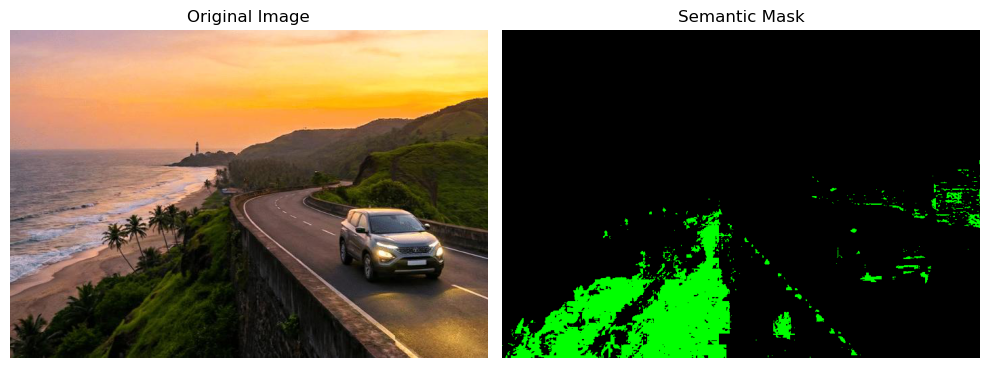

In [2]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Load an image from your computer
image = Image.open(
    r"C:\Users\nanda\OneDrive\Pictures\Image\car.jpg"
).convert("RGB")

image_array = np.array(image)

# Create a mask for green-colored pixels
green_mask = (
    (image_array[:, :, 1] > image_array[:, :, 0] * 1.2) &
    (image_array[:, :, 1] > image_array[:, :, 2])
)

# Create a colored semantic mask
semantic_mask = np.zeros_like(image_array)

# Green pixels receive the green class color
semantic_mask[green_mask] = [0, 255, 0]

# Display original image and mask
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image_array)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(semantic_mask)
plt.title("Semantic Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

Python explanation:
- image_array stores the image's pixel values.
- green_mask identifies pixels that satisfy the green-color conditions.
- semantic_mask assigns green to selected pixels and black to the remaining pixels.
- imshow() displays the original image and the mask.
Remember: A real semantic segmentation model learns classes such as roads, people, and cars from training images. The example above uses color rules only.

# 3. Instance Segmentation

## Simple Concept

Instance segmentation identifies individual objects in an image and creates a separate pixel mask for each object.

It identifies both:
- **Class:** What the object is, such as a car or person.
- **Instance:** Which individual object it is.

## Example

Imagine an image containing three cars.

Instance segmentation identifies:
- Car 1 → Mask 1
- Car 2 → Mask 2
- Car 3 → Mask 3

Even though all three objects belong to the same class, each car receives its own separate mask.

## How It Works

1. The image is given to an instance segmentation model.
2. The model detects individual objects.
3. It identifies the class of each object.
4. It generates a separate pixel mask for each detected object.

## Semantic vs Instance Segmentation

- **Semantic segmentation:** All cars receive the same class label.
- **Instance segmentation:** Each car receives its own separate mask.

## Real-World Applications

- **Autonomous vehicles:** Identify and separate individual cars and pedestrians.
- **Robotics:** Locate individual objects for picking and handling.
- **Healthcare:** Separate individual cells in microscope images.
- **Retail:** Identify and count individual products.

## Key Point

Instance segmentation identifies individual objects and separates their exact pixel regions, even when multiple objects belong to the same class.

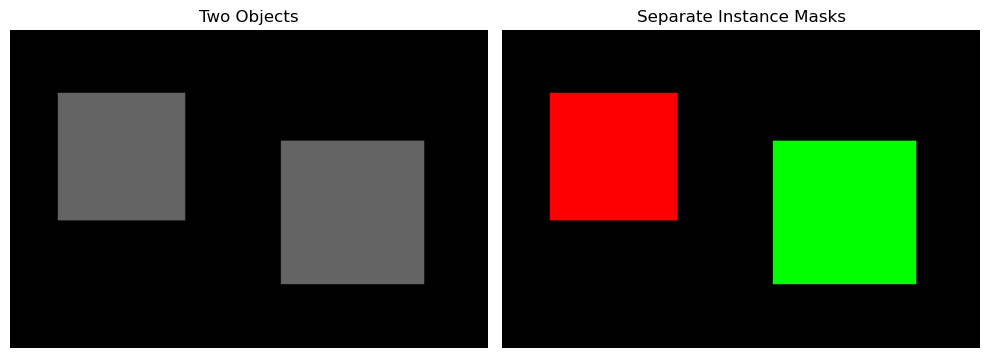

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Create an empty image
height, width = 200, 300
image = np.zeros((height, width, 3), dtype=np.uint8)

# Simulate two objects
image[40:120, 30:110] = [100, 100, 100]
image[70:160, 170:260] = [100, 100, 100]

# Create a separate mask for each object
mask1 = np.zeros((height, width), dtype=bool)
mask2 = np.zeros((height, width), dtype=bool)

mask1[40:120, 30:110] = True
mask2[70:160, 170:260] = True

# Assign different colors to each instance
instance_mask = np.zeros_like(image)
instance_mask[mask1] = [255, 0, 0]
instance_mask[mask2] = [0, 255, 0]

# Display the result
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Two Objects")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(instance_mask)
plt.title("Separate Instance Masks")
plt.axis("off")

plt.tight_layout()
plt.show()

Python explanation:
- mask1 represents the first object.
- mask2 represents the second object.
- Each mask identifies the pixels belonging to its own object.
- Different colors make the individual masks easy to distinguish.
The objects here are simulated rectangles, not real detected cars. A trained instance segmentation model can produce masks that follow the actual object boundaries.

# 4. Panoptic Segmentation

## Simple Concept

Panoptic segmentation combines semantic segmentation and instance segmentation to provide a complete understanding of an image.

It handles two types of regions:

- **Things:** Countable objects with individual identities, such as cars, people, and bicycles.
- **Stuff:** Background or uncountable regions, such as roads, sky, grass, and water.

## Example

Imagine an image containing two cars, one person, a road, and the sky.

Panoptic segmentation identifies:

- Car 1 → Individual object mask
- Car 2 → Individual object mask
- Person 1 → Individual object mask
- Road → Semantic region
- Sky → Semantic region

Each pixel is assigned a class, and individual countable objects receive separate identities.

## How It Works

1. The image is given to a panoptic segmentation model.
2. The model identifies classes across the image.
3. It separates individual objects belonging to countable classes.
4. It combines the predictions into a unified segmentation result.

## Comparison

- **Semantic segmentation:** Identifies the class of every pixel.
- **Instance segmentation:** Identifies individual objects and their masks.
- **Panoptic segmentation:** Combines both approaches to label the entire image and distinguish individual objects.

## Real-World Applications

- **Autonomous driving:** Understand cars, pedestrians, roads, and sidewalks together.
- **Robotics:** Identify movable objects and surrounding surfaces.
- **Urban planning:** Analyze buildings, roads, vegetation, and vehicles.
- **Scene understanding:** Help AI systems understand complete visual environments.

## Key Point

Panoptic segmentation provides a unified pixel-level understanding of an image, including both individual objects and background regions.

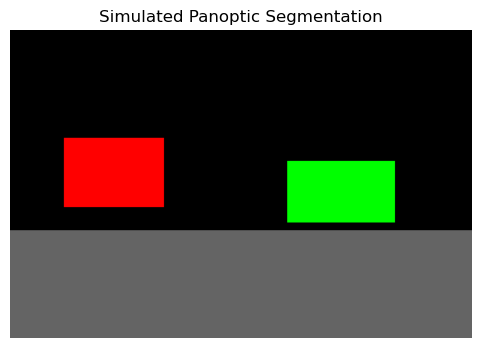

In [4]:
import numpy as np
import matplotlib.pyplot as plt

height, width = 200, 300

# Class IDs:
# 0 = Background
# 1 = Road
# 2 = Car

class_map = np.zeros((height, width), dtype=np.uint8)

# Assign road class
class_map[130:200, :] = 1

# Create separate instance IDs for the cars
instance_map = np.zeros((height, width), dtype=np.uint8)

class_map[70:115, 35:100] = 2
instance_map[70:115, 35:100] = 1

class_map[85:125, 180:250] = 2
instance_map[85:125, 180:250] = 2

# Create a color visualization
visual = np.zeros((height, width, 3), dtype=np.uint8)

visual[class_map == 1] = [100, 100, 100]  # Road
visual[instance_map == 1] = [255, 0, 0]   # Car 1
visual[instance_map == 2] = [0, 255, 0]   # Car 2

plt.figure(figsize=(8, 4))
plt.imshow(visual)
plt.title("Simulated Panoptic Segmentation")
plt.axis("off")
plt.show()

Python explanation:
- class_map stores the class assigned to each pixel.
- instance_map distinguishes individual cars.
- The road receives a shared class label, while each car has its own instance ID.
- Different colors make the regions easy to understand.
Remember: This is a simulated visualization, not an AI model prediction. A real panoptic segmentation model predicts these regions from an input image.

# 5. Pixel-Level Classification

## Simple Concept

Pixel-level classification means assigning a class label to each pixel in an image.

In image segmentation, the model examines visual patterns and predicts what each pixel represents.

For example, pixels may belong to classes such as:
- Car
- Road
- Person
- Sky
- Tree

The collection of predicted pixel labels forms a **segmentation mask**.

## How It Works

1. The input image is converted into numerical pixel values.
2. A segmentation model processes the image.
3. The model predicts a class score for each pixel and each possible class.
4. The class with the highest score is selected for each pixel.
5. The predictions form a pixel-level class map.

## Example

Suppose a model recognizes three classes: Road, Car, and Sky.

A small section of its predicted class map might look like this:

| Road | Road | Road |
|---|---|---|
| Road | Car | Car |
| Sky | Sky | Sky |

Each cell represents a pixel or a simplified pixel region, and each label indicates its predicted class.

## Important Difference

Pixel-level classification does not necessarily distinguish separate objects of the same class.

For example, two cars can both receive the class label `Car`. Instance segmentation adds separate identities for individual cars.

## Real-World Applications

- Medical image analysis
- Road and pedestrian detection
- Satellite image analysis
- Agricultural image analysis

## Key Point

Pixel-level classification is the basic prediction process behind semantic segmentation: each pixel receives a class label.

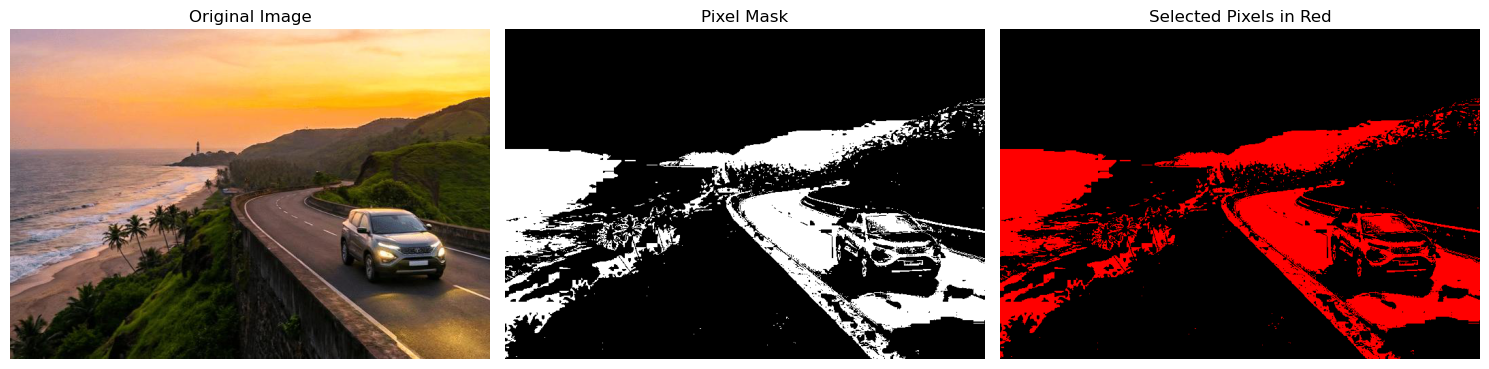

In [7]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Load your uploaded image
image = Image.open(r"C:\Users\nanda\OneDrive\Pictures\Image\car.jpg").convert("RGB")
image_array = np.array(image)

# Create a simple mask based on dark gray pixels
red = image_array[:, :, 0]
green = image_array[:, :, 1]
blue = image_array[:, :, 2]

car_mask = (
    (red > 60) & (red < 180) &
    (green > 50) & (green < 170) &
    (blue > 40) & (blue < 150) &
    (np.abs(red.astype(int) - green.astype(int)) < 35)
)

# Create a visualization of selected pixels
segmented_image = np.zeros_like(image_array)
segmented_image[car_mask] = [255, 0, 0]

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image_array)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(car_mask, cmap="gray")
plt.title("Pixel Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(segmented_image)
plt.title("Selected Pixels in Red")
plt.axis("off")

plt.tight_layout()
plt.show()

Python explanation:
- image contains the RGB pixel values.
- class_map stores one class ID per pixel.
- The color rules assign the IDs for sky, road, and car.
- imshow() displays the resulting class map.
Note: This example works because the simulated regions have known colors. Real images have varied colors and lighting, so trained segmentation models use learned visual features instead

# 6. Masks in Image Segmentation

## Simple Concept

A mask is an image that identifies which pixels belong to a selected object or region.

In segmentation, a mask helps separate an object from its background.

For example, in your uploaded coastal road image, we can create a mask for the car.

- **White pixels (255):** Pixels selected as part of the car.
- **Black pixels (0):** Pixels outside the selected region.

A mask can also use multiple class IDs or different colors to represent multiple objects and regions.

## Types of Masks

- **Binary mask:** Separates one selected object or region from everything else.
- **Semantic mask:** Assigns a class label to every pixel, such as car, road, or sky.
- **Instance masks:** Creates a separate mask for each individual object.

## Why Are Masks Useful?

Masks help AI systems identify object boundaries and measure or analyze the pixels belonging to objects.

## Real-World Applications

- **Autonomous driving:** Separate vehicles from roads and surroundings.
- **Medical imaging:** Highlight organs or affected regions.
- **Photo editing:** Select an object without changing the background.
- **Agriculture:** Identify crop regions in images.

## Key Point

A mask represents the pixel locations belonging to an object or class. Its accuracy depends on how accurately those pixels are identified.

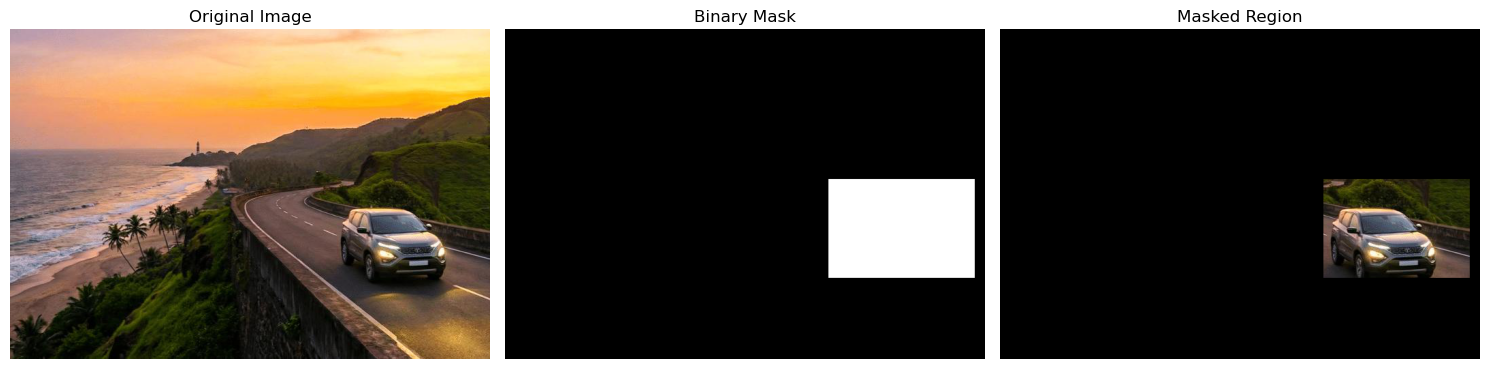

In [9]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Load your uploaded image
image = Image.open(r"C:\Users\nanda\OneDrive\Pictures\Image\car.jpg").convert("RGB")
image_array = np.array(image)

# Create a blank binary mask
mask = np.zeros(image_array.shape[:2], dtype=np.uint8)

# Rough region containing the car
# Coordinates are (y, x)
mask[220:365, 475:690] = 255

# Apply the mask to the original image
masked_image = image_array.copy()
masked_image[mask == 0] = 0

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image_array)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray", vmin=0, vmax=255)
plt.title("Binary Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(masked_image)
plt.title("Masked Region")
plt.axis("off")

plt.tight_layout()
plt.show()

Python explanation:
- mask creates a black image with the same height and width as your photo.
- mask[220:365, 475:690] = 255 marks a rectangular area in white.
- masked_image[mask == 0] = 0 makes all pixels outside that area black.
- The final image shows only the selected rectangular region.
Remember: A manually drawn rectangle demonstrates how a mask works. A trained segmentation model can predict a mask that follows the actual outline of the car.

## 1. Simple Concept

**Bounding Box:** A rectangular box drawn around an object to identify its location in an image.

**Mask:** A pixel-level outline that identifies the exact area occupied by an object.

### 2. Bounding Box

A bounding box uses a rectangle to locate an object.

- Identifies approximately where the object is located.
- Includes some background around the object.
- Commonly used in object detection.

**Example:** A rectangle around a rabbit includes the rabbit and some surrounding grass.

### 3. Mask

A mask identifies the pixels belonging to an object.

- Follows the object's shape more closely.
- Separates the object from the background.
- Commonly used in image segmentation.

**Example:** A rabbit mask highlights the rabbit's body and excludes the surrounding grass.

### 4. Main Difference

A bounding box answers: **Where is the object?**

A mask answers: **Which pixels belong to the object?**

### 5. Real-World Applications

- **Bounding boxes:** Detecting cars, people, and traffic signs.
- **Masks:** Separating road areas, identifying damaged parts, and outlining objects in medical images.

### 6. Key Point

Bounding boxes provide rectangular object locations, while masks provide pixel-level object shapes.

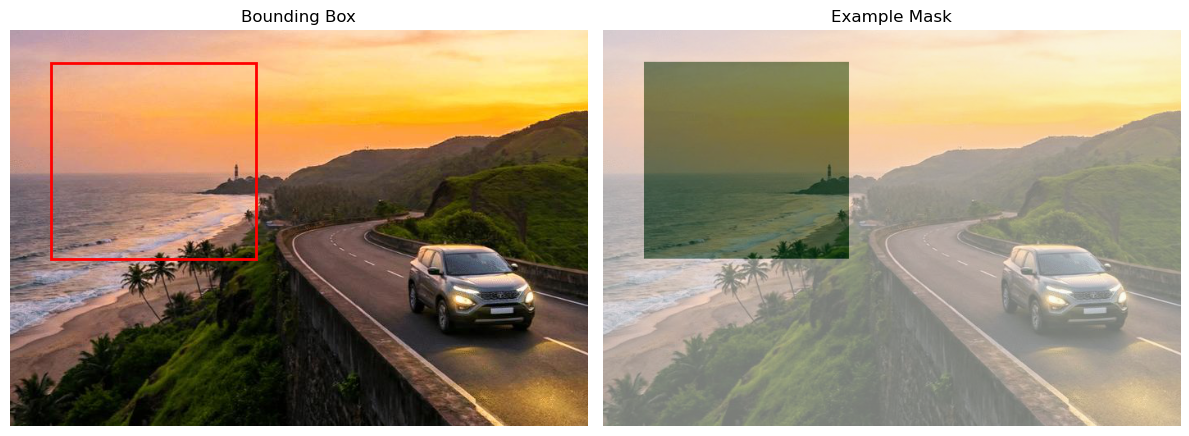

In [11]:

from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

# Load your local image
image_path = r"C:\Users\nanda\OneDrive\Pictures\Image\car.jpg"

image = Image.open(image_path).convert("RGB")
image_array = np.array(image)

# Example bounding box coordinates
# Change these values to fit your object
x1, y1, x2, y2 = 50, 40, 300, 280

# Example mask: a rectangular region for demonstration
mask = np.zeros(image_array.shape[:2], dtype=bool)
mask[y1:y2, x1:x2] = True

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bounding box
axes[0].imshow(image)
box = patches.Rectangle(
    (x1, y1), x2 - x1, y2 - y1,
    linewidth=2, edgecolor="red", facecolor="none"
)
axes[0].add_patch(box)
axes[0].set_title("Bounding Box")
axes[0].axis("off")

# Mask overlay
axes[1].imshow(image)
axes[1].imshow(mask, cmap="Greens", alpha=0.5)
axes[1].set_title("Example Mask")
axes[1].axis("off")

plt.tight_layout()
plt.show()


### Simple Concept

A **Fully Convolutional Network (FCN)** is a deep learning architecture designed to classify image pixels and produce a segmentation map.

Unlike a traditional image classification model that predicts one label for an entire image, an FCN produces spatial predictions across the image.

### How it works

1. **Input image:** Receives an image.
2. **Convolution layers:** Extract features such as edges, textures, and shapes.
3. **Upsampling:** Increases the spatial resolution of the feature maps.
4. **Segmentation output:** Produces a class prediction for each pixel.

### Real-World Applications

- Separating roads from surroundings in driving images.
- Identifying buildings in satellite images.
- Segmenting objects in general-purpose images.

### Key Point

FCN converts image features into a pixel-level segmentation map. It is a foundational architecture for semantic segmentation.

### Simple Concept

**U-Net** is a deep learning architecture commonly used for image segmentation. It identifies the shape and location of objects by predicting a class for each pixel.

It is especially popular in medical imaging.

### How it works

U-Net has three main parts:

1. **Encoder:** Extracts image features and learns what is present in the image.
2. **Bottleneck:** Combines the deeper features learned by the encoder.
3. **Decoder:** Reconstructs spatial details and generates the segmentation map.

**Skip connections** transfer features from the encoder to the decoder. This helps preserve important details, such as object boundaries.

### Real-World Applications

- Medical images: Identifying organs and tumors.
- Agriculture: Separating plants from soil.
- Satellite images: Identifying roads and buildings.

### Key Point

U-Net combines deep image features with spatial details using skip connections, making it useful when accurate object boundaries matter.